# 06 — Werkzeuge und MCP

**Lernziel.** Du bindest fertige Bausteine an deinen Agenten an: den Tool-Knoten von
LangGraph, eine Websuche über Tavily und einen eigenen MCP-Server. Zum Schluss
lernst du Entscheidungsmodelle kennen, die wählen statt schreiben. Knoten und Kanten
aus Woche 5 bleiben dabei unverändert.

**Dauer.** Rund 50 Minuten.

**Voraussetzungen.** Notebook 05 gelaufen. Für die Websuche ein Tavily-Konto — das
richten wir in diesem Notebook ein. Ohne Konto läuft das Notebook trotzdem durch.

**Empfohlen:** lokal ausführen, zum Beispiel in PyCharm.

---

Wieder am selben Fall: ein Prototyp, der Fragen zu einer Reise mit SWISS beantwortet.
SWISS ist ein reales Unternehmen; dies hier ist eine Übung und kein offizieller Dienst.

## Setup

Dieselben Zellen wie in Woche 5: Installation, Modell, Schlüssel, Tracing,
Verbindungstest.

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [1]:
LLM_MODEL = "gpt-5.6-luna"
LLM_BASE_URL = "https://litellm.engines.aisl.science/v1"

# Weitere Modelle auf demselben Proxy:
#   "azure_ai/mistral-large-3"

In [2]:
import os
from dotenv import load_dotenv
from getpass import getpass

# load_dotenv liest die .env, überschreibt aber nichts, was schon gesetzt ist.
load_dotenv()

if not os.environ.get("LITELLM_API_KEY"):
    os.environ["LITELLM_API_KEY"] = getpass("LITELLM_API_KEY: ")

In [3]:
# vor dem ersten Modellaufruf setzen, sonst greift das Tracing nicht
if os.environ.get("LANGSMITH_API_KEY"):
    os.environ["LANGSMITH_TRACING"] = "true"
    os.environ["LANGSMITH_PROJECT"] = "genai_swiss_cw6"
    print("Tracing läuft. Projekt:", os.environ["LANGSMITH_PROJECT"])
else:
    os.environ["LANGSMITH_TRACING"] = "false"
    print("Kein LANGSMITH_API_KEY gefunden — weiter ohne Tracing.")

Tracing läuft. Projekt: genai_swiss_cw6


In [4]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model=LLM_MODEL,
    base_url=LLM_BASE_URL,
    api_key=os.environ["LITELLM_API_KEY"],
    temperature=0,
)

print(llm.invoke("Antworte mit einem Wort: bereit?").content)

Bereit


## Stand aus Woche 5

Die folgende Zelle ist der fertige Graph der letzten Woche: Prompts, `fare_lookup`,
die Schemas, der State, alle Knoten und Kanten, `build_graph()` und `ask()`. Wer
letzte Woche gefehlt hat, führt sie aus und liest weiter — verstehen muss man sie
hier nicht.

```
START → classify → reject → END
START → classify → answer ⇄ tools → respond → END
```

In [10]:
import operator, os
from typing import Literal
from typing_extensions import Annotated, TypedDict
from pydantic import BaseModel, Field
from langchain.messages import AIMessage, AnyMessage, HumanMessage, SystemMessage, ToolMessage
from langchain.tools import tool
from langgraph.graph import StateGraph, START, END

SYSTEM_PROMPT = """Du beantwortest Fragen zu Tarifen und Gepäck bei SWISS.
Fakten: Schlage Konditionen und Gebühren mit fare_lookup nach. Erfinde nichts, auch keine Kontaktdaten.
Fehlt eine Angabe, frage nach.
Antwortstil: Sprich die Person mit «Sie» an, antworte in der Sprache der Frage, höchstens vier Sätze.
Kennzeichnung: Du bist ein Prototyp aus einer Lehrveranstaltung, kein offizieller Dienst von SWISS."""

CLASSIFY_PROMPT = """Entscheide, ob eine Frage zu einem Assistenten für SWISS gehört, und bestimme ihr Thema.
Zuständig: Flüge, Tarife, Gepäck, Buchung, Umbuchung, Erstattung bei SWISS, Fragen an den Assistenten.
Nicht zuständig: andere Fluggesellschaften und alles andere."""

FARES = {
    "economy light":   {"carry_on": "1 Stück, 8 kg", "checked_baggage": "kein Freigepäck",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "nicht umbuchbar",
                        "seat_selection": "ab CHF 15"},
    "economy classic": {"carry_on": "1 Stück, 8 kg", "checked_baggage": "1 Stück, 23 kg",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "CHF 80",
                        "seat_selection": "ab CHF 15"},
    "economy flex":    {"carry_on": "1 Stück, 8 kg", "checked_baggage": "1 Stück, 23 kg",
                        "extra_bag_fee": "CHF 60", "rebooking_fee": "kostenlos",
                        "seat_selection": "inklusive"},
}


@tool
def fare_lookup(fare: str) -> str:
    """Schlägt Konditionen und Nebenkosten eines SWISS-Tarifs nach.

    Liefert Handgepäck, Freigepäck, Gebühr für ein zusätzliches Gepäckstück,
    Umbuchungsgebühr und Sitzplatzwahl.
    Mögliche Tarife: Economy Light, Economy Classic, Economy Flex.
    """
    data = FARES.get(fare.strip().lower())
    if data is None:
        return f"Tarif '{fare}' ist nicht in der Tabelle. Bekannt sind: {', '.join(FARES)}."
    return ", ".join(f"{k}: {v}" for k, v in data.items())


tools = [fare_lookup]
tools_by_name = {t.name: t for t in tools}
llm_with_tools = llm.bind_tools(tools)


class Classification(BaseModel):
    reason: str = Field(description="Begründung in einem Satz")
    in_scope: bool = Field(description="True, wenn die Frage in den Zuständigkeitsbereich fällt")
    category: Literal["fare", "baggage", "booking", "refund", "other"] = Field(description="Thema der Frage")


class AgentResponse(BaseModel):
    answer: str = Field(description="Antwort an die Kundin oder den Kunden")
    fare: str | None = Field(description="Tarif, um den es geht, falls einer genannt wird")
    needs_human: bool = Field(description="True bei Beschwerden, Entschädigungsforderungen, Notlagen unterwegs "
                                          "oder wenn eine Buchung geändert werden muss")


class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]
    in_scope: bool
    category: str
    tools_used: Annotated[list[str], operator.add]
    response: AgentResponse


classifier = llm.with_structured_output(Classification, method="json_schema")
responder = llm.with_structured_output(AgentResponse, method="json_schema")


def classify(state: AgentState):
    result = classifier.invoke([SystemMessage(content=CLASSIFY_PROMPT), state["messages"][-1]])
    return {"in_scope": result.in_scope, "category": result.category}


def reject(state: AgentState):
    text = "Dabei kann ich leider nicht helfen. Ich beantworte nur Fragen zu SWISS."
    return {"messages": [AIMessage(content=text)],
            "response": AgentResponse(answer=text, fare=None, needs_human=False)}


def answer(state: AgentState):
    return {"messages": [llm_with_tools.invoke([SystemMessage(content=SYSTEM_PROMPT)] + state["messages"])]}


def call_tools(state: AgentState):
    tool_calls = state["messages"][-1].tool_calls
    results = []
    for tool_call in tool_calls:
        result = tools_by_name[tool_call["name"]].invoke(tool_call["args"])
        results.append(ToolMessage(content=str(result), tool_call_id=tool_call["id"]))
    return {"messages": results, "tools_used": [c["name"] for c in tool_calls]}


def respond(state: AgentState):
    messages = ([SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
                + [HumanMessage(content="Übernimm deine letzte Antwort unverändert in das vorgegebene Format.")])
    return {"response": responder.invoke(messages)}


def route_after_classify(state: AgentState):
    return "answer" if state["in_scope"] else "reject"


def route_after_answer(state: AgentState):
    return "tools" if state["messages"][-1].tool_calls else "respond"


def build_graph():
    builder = StateGraph(AgentState)
    builder.add_node("classify", classify)
    builder.add_node("reject", reject)
    builder.add_node("answer", answer)
    builder.add_node("tools", call_tools)
    builder.add_node("respond", respond)
    builder.add_edge(START, "classify")
    builder.add_conditional_edges("classify", route_after_classify, ["answer", "reject"])
    builder.add_edge("reject", END)
    builder.add_conditional_edges("answer", route_after_answer, ["tools", "respond"])
    builder.add_edge("tools", "answer")
    builder.add_edge("respond", END)
    return builder.compile()


graph = build_graph()


def ask(question):
    return graph.invoke({"messages": [HumanMessage(content=question)]})["response"].answer

print(ask("Was kostet eine Umbuchung in Economy Classic?"))

Die Umbuchungsgebühr im Tarif **Economy Classic** beträgt **CHF 80**.  
Hinzu können allfällige Tarifdifferenzen kommen. Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


Heute bleibt dieser Graph, wie er ist. Was sich ändert, ist nur die Liste `tools`
und der Knoten, der sie ausführt. Vier Schritte, dazu ein fünfter mit einem eigenen kleinen Graphen:

1. Der fertige Tool-Knoten `ToolNode` statt unserer eigenen Schleife.
2. Ein fertiges Werkzeug: die Websuche über Tavily.
3. Werkzeuge aus einem eigenen Prozess: ein MCP-Server.
4. Was passiert, wenn ein Werkzeug scheitert — und wie man es nochmals versucht.
5. Entscheidungsmodelle: ein Modell, das wählt statt schreibt.

## 1. Der fertige Tool-Knoten

In Woche 5 haben wir den Knoten `tools` selbst geschrieben, damit man sieht, dass
dahinter nur eine Schleife steckt. Jetzt nehmen wir den fertigen Baustein von
LangGraph, den `ToolNode`. Er macht dasselbe und noch etwas mehr:

- Er führt **asynchrone** Werkzeuge aus. Das brauchen wir in Schritt 3 für MCP.
- Er kann einem Werkzeug Zugriff auf den State geben, wenn es danach fragt. Unser
  eigener Knoten hat nur die Argumente des Modells weitergereicht. Dazu gleich ein
  Beispiel.
- Er schreibt Fehler eines Werkzeugs auf Wunsch als `ToolMessage` in den Verlauf,
  statt den ganzen Graphen abzubrechen. Dazu mehr in Schritt 4.

Eines kann er nicht: Unser Feld `tools_used` kennt er nicht. Deshalb bleibt
`call_tools` als dünne Hülle stehen. Sie lässt den `ToolNode` arbeiten und trägt
danach die Namen der Werkzeuge ein — wie in Woche 5 vom Code, nicht vom Modell.

In [7]:
from langgraph.prebuilt import ToolNode

tool_node = ToolNode(tools)


def call_tools(state: AgentState):
    """Führt die angeforderten Werkzeuge mit dem fertigen ToolNode aus."""
    result = tool_node.invoke(state)
    tool_names = [c["name"] for c in state["messages"][-1].tool_calls]
    return {"messages": result["messages"], "tools_used": tool_names}


graph = build_graph()

result = graph.invoke({"messages": [HumanMessage(content="Was kostet eine Umbuchung in Economy Classic?")]})
print("tools_used:", result["tools_used"])
print(result["response"].answer)

tools_used: ['fare_lookup']
Die Umbuchungsgebühr im Tarif **Economy Classic** beträgt **CHF 80**.  
Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


`build_graph()` sucht `call_tools` erst beim Aufruf. Darum genügt es, die Funktion
neu zu definieren und den Graphen neu zu bauen — an Knoten und Kanten ändert sich
nichts.

### Ein Werkzeug liest den State

Was der `ToolNode` mehr kann, zeigen wir an `fare_lookup`. Bisher liefert es immer
alle Konditionen eines Tarifs. Dabei weiss der Graph schon, worum es geht: `classify`
hat das Thema in `category` geschrieben. Bei einer Gepäckfrage soll das Werkzeug nur
die Gepäckangaben liefern.

Dazu bekommt `fare_lookup` einen zweiten Parameter `runtime: ToolRuntime`. Den füllt
nicht das Modell, sondern der `ToolNode`, und in `runtime.state` steht der State.
Unsere Schleife aus Woche 5 hätte das nicht gekonnt: Sie hat nur die Argumente des
Modells weitergereicht.

In [8]:
from langchain.tools import ToolRuntime

BAGGAGE_KEYS = ["carry_on", "checked_baggage", "extra_bag_fee"]


@tool
def fare_lookup(fare: str, runtime: ToolRuntime) -> str:
    """Schlägt Konditionen und Nebenkosten eines SWISS-Tarifs nach.

    Liefert Handgepäck, Freigepäck, Gebühr für ein zusätzliches Gepäckstück,
    Umbuchungsgebühr und Sitzplatzwahl.
    Mögliche Tarife: Economy Light, Economy Classic, Economy Flex.
    """
    data = FARES.get(fare.strip().lower())
    if data is None:
        return f"Tarif '{fare}' ist nicht in der Tabelle. Bekannt sind: {', '.join(FARES)}."
    if runtime.state["category"] == "baggage":
        data = {k: v for k, v in data.items() if k in BAGGAGE_KEYS}
    return ", ".join(f"{k}: {v}" for k, v in data.items())


print("Das Modell sieht nur:", list(fare_lookup.tool_call_schema.model_json_schema()["properties"]))

Das Modell sieht nur: ['fare']


Für das Modell hat sich nichts geändert: Es sieht weiterhin nur den Parameter `fare`.
`runtime` taucht in der Beschreibung nicht auf, das Modell kann ihn also weder
ausfüllen noch fälschen.

Weil `fare_lookup` neu definiert ist, müssen `tools`, `llm_with_tools` und
`tool_node` neu entstehen. Danach eine Gepäckfrage — und ein Blick auf das, was das
Werkzeug zurückgegeben hat.

In [9]:
tools = [fare_lookup]
llm_with_tools = llm.bind_tools(tools)
tool_node = ToolNode(tools)

graph = build_graph()

result = graph.invoke({"messages": [HumanMessage(content="Wie viel Gepäck darf ich in Economy Classic mitnehmen?")]})
print("category:     ", result["category"])
print("Werkzeug gab: ", [m.content for m in result["messages"] if isinstance(m, ToolMessage)])
print(result["response"].answer)

category:      baggage
Werkzeug gab:  ['carry_on: 1 Stück, 8 kg, checked_baggage: 1 Stück, 23 kg, extra_bag_fee: CHF 60']
Sie dürfen im Tarif **Economy Classic** mitnehmen:

- **1 Handgepäckstück** bis **8 kg**
- **1 aufgegebenes Gepäckstück** bis **23 kg**
- Ein zusätzliches Gepäckstück kostet **CHF 60**.

Hinweis: Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


## 2. Ein fertiges Werkzeug: Websuche mit Tavily

Nicht jedes Werkzeug muss man selbst schreiben. LangChain hat eine lange Liste
fertiger Werkzeuge:
[docs.langchain.com/oss/python/integrations/tools](https://docs.langchain.com/oss/python/integrations/tools)

Wir nehmen **Tavily**, eine Suchmaschine für Agenten. Sie liefert statt einer
Trefferliste mit Werbung kurze Textauszüge mit Adresse — genau das Format, mit dem
ein Modell arbeiten kann.

**Jetzt ein Konto anlegen:** [tavily.com](https://tavily.com) → registrieren →
Schlüssel kopieren und als `TAVILY_API_KEY` in die `.env` schreiben. Gratis sind
1000 Anfragen pro Monat, keine Kreditkarte.

Wer das gerade nicht kann, macht trotzdem weiter — der Agent hat dann einfach keine
Websuche.

In [10]:
from langchain_tavily import TavilySearch

load_dotenv()  # falls der Schlüssel eben erst in die .env kam

if os.environ.get("TAVILY_API_KEY"):
    web_search = TavilySearch(max_results=3)
    tools = [fare_lookup, web_search]
    print("Websuche bereit. Name für das Modell:", web_search.name)
else:
    tools = [fare_lookup]
    print("Kein TAVILY_API_KEY gefunden — weiter ohne Websuche.")

Websuche bereit. Name für das Modell: tavily_search


Ein fertiges Werkzeug hat dieselben drei Teile wie unser eigenes: einen Namen
(`tavily_search`), eine Beschreibung und Parameter. Geschrieben hat sie jemand
anderes, aber das Modell liest sie genau gleich wie den Docstring von `fare_lookup`.

Die Liste `tools` hat sich geändert. Also müssen `llm_with_tools` und `tool_node`
neu entstehen, damit das Modell das neue Werkzeug kennt und der Knoten es ausführen
kann. Der Graph selbst bleibt.

In [11]:
llm_with_tools = llm.bind_tools(tools)
tool_node = ToolNode(tools)

graph = build_graph()

Eine Frage, die nicht in `FARES` steht, aber zu SWISS gehört. Der System-Prompt aus
Woche 5 kennt die Websuche noch nicht. Mal sehen, ob das Modell sie trotzdem benutzt.

In [12]:
WEB_QUESTION = "Fliegt SWISS ab Zürich direkt nach Bangkok?"

result = graph.invoke({"messages": [HumanMessage(content=WEB_QUESTION)]})
print("tools_used:", result["tools_used"])
print(result["response"].answer)

tools_used: ['tavily_search', 'tavily_search']
Ja, SWISS fliegt direkt von Zürich (ZRH) nach Bangkok (BKK). Die Verbindung dauert etwa 10 Stunden und 55 Minuten; laut SWISS gibt es ungefähr 14 wöchentliche Verbindungen. Änderungen je nach Reisedatum sind möglich – bitte prüfen Sie den konkreten Flugplan.  
*Hinweis: Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.*


Das Modell findet die Websuche allein: Name und Beschreibung des Werkzeugs
genügen. Was fehlt, ist eine Regel für das Ergebnis. Die Antwort klingt so sicher
wie eine aus `FARES`, sagt aber nicht, dass sie aus dem Internet stammt.

Ein neues Werkzeug braucht deshalb oft auch eine Zeile im System-Prompt: wann es zu
benutzen ist und was mit dem Ergebnis geschieht.

In [13]:
SYSTEM_PROMPT = SYSTEM_PROMPT + """
Websuche: Was nicht in den Tarifdaten steht, etwa Flugverbindungen, suchst du mit tavily_search.
Nenne dann die Quelle (Adresse) und sage, dass es eine Information aus dem Internet ist."""

result = graph.invoke({"messages": [HumanMessage(content=WEB_QUESTION)]})
print("tools_used:", result["tools_used"])
print(result["response"].answer)

tools_used: ['tavily_search']
Ja, SWISS bietet Direktflüge von Zürich (ZRH) nach Bangkok (BKK) an. Die Flugzeit beträgt etwa 10 Stunden 55 Minuten; laut SWISS gibt es ungefähr 14 Verbindungen pro Woche. Quelle: [swiss.com](https://www.swiss.com/lhg/ch/de/o-d/cy-cy/zuerich-bangkok) – diese Angaben stammen aus dem Internet und können sich ändern. Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


`answer` liest `SYSTEM_PROMPT` bei jedem Aufruf neu. Darum wirkt die Änderung, ohne
dass der Graph neu gebaut werden muss.

**Vorsicht mit dem offenen Netz.** Die Suche liefert, was sie findet: Reiseportale,
alte Pressemitteilungen, Foren. Das Modell kann nicht prüfen, ob eine Quelle
vertrauenswürdig oder aktuell ist. Deshalb arbeiten wir in Woche 7 mit ausgewählten
Dokumenten — und die Websuche wird dort zum Rückfall für das, was in den Dokumenten
nicht steht.

## 3. Einen MCP-Server anbinden

Bisher lagen die Werkzeuge im Notebook. **MCP** (Model Context Protocol) ist ein
offener Standard, mit dem Werkzeuge in einem **eigenen Prozess** laufen und über
eine einheitliche Schnittstelle angeboten werden. Der Vorteil: Dieselben Werkzeuge
lassen sich von jedem MCP-fähigen Programm nutzen, nicht nur von diesem Notebook.

Unser Server steht in `05_custom_mcp_server.py` — schau kurz hinein, er ist kurz.
Er wird als eigener Prozess gestartet und über die Standardeingabe angesprochen.

> **Einzige Ausnahme im ganzen Modul:** Der MCP-Client arbeitet asynchron, deshalb
> steht hier `await`. In Jupyter funktioniert das direkt in der Zelle. Das ist eine
> Eigenheit dieser Bibliothek und kein Muster, das im übrigen Code vorkommt.

In [14]:
import sys
from langchain_mcp_adapters.client import MultiServerMCPClient

client = MultiServerMCPClient({
    "swiss": {
        "command": sys.executable,             # derselbe Python wie dieses Notebook
        "args": ["05_custom_mcp_server.py"],
        "transport": "stdio",                  # Kommunikation über die Standardeingabe
    }
})

mcp_tools = await client.get_tools()

for t in mcp_tools:
    print(f"{t.name:10} {t.description}")

add        Add two numbers
multiply   Multiply two numbers
get_quote  Fetch the quote for a flight from ZRH to a destination (city_name)


Die Werkzeuge vom Server sehen aus wie unsere eigenen. Ein Unterschied bleibt aber:
Sie sind **nur asynchron** aufrufbar. Ein `tool.invoke(...)` scheitert mit
`StructuredTool does not support sync invocation` — es muss `await tool.ainvoke(...)`
sein.

In [15]:
get_quote = [t for t in mcp_tools if t.name == "get_quote"][0]

print(await get_quote.ainvoke({"city_name": "London"}))

[{'type': 'text', 'text': 'A flight from Zurich to London (LHR) costs 180 CHF.', 'id': 'lc_5b6855ea-c51b-4b48-9983-17a33da28e21'}]


Damit der Agent diese Werkzeuge benutzen kann, muss `call_tools` den `ToolNode`
asynchron aufrufen (`ainvoke`), und der Graph wird mit `await graph.ainvoke(...)`
gestartet. Sonst ändert sich nichts: gleiche Knoten, gleiche Kanten.

Der `ToolNode` führt im asynchronen Fall auch unsere synchronen Werkzeuge aus.
Deshalb dürfen alle Sorten in derselben `tools`-Liste stehen. Wir hängen die
MCP-Werkzeuge an die bisherige Liste an: `fare_lookup` und, falls der Schlüssel
da ist, die Websuche bleiben dabei.

In [16]:
tools = tools + mcp_tools
llm_with_tools = llm.bind_tools(tools)
tool_node = ToolNode(tools)


async def call_tools(state: AgentState):
    """Wie oben, nur mit ainvoke — wegen der MCP-Werkzeuge."""
    result = await tool_node.ainvoke(state)
    tool_names = [c["name"] for c in state["messages"][-1].tool_calls]
    return {"messages": result["messages"], "tools_used": tool_names}


graph = build_graph()

result = await graph.ainvoke({"messages": [HumanMessage(content="Was kostet ein Flug von Zürich nach London? Ein Richtpreis genügt.")]})
print("tools_used:", result["tools_used"])
print(result["response"].answer)

tools_used: ['get_quote']
Ein Richtpreis für einen Flug von Zürich nach London (LHR) beträgt **ca. 180 CHF**.  
Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


Im Trace (Projekt `genai_swiss_cw6`) siehst du denselben Weg wie in Woche 5:
`classify → answer → tools → answer → respond`. Dass `get_quote` in einem anderen
Prozess lief, merkt der Graph nicht.

## 4. Wenn ein Werkzeug scheitert

Werkzeuge rufen Server, Datenbanken und Webdienste auf, und die fallen manchmal aus
oder bekommen eine Eingabe, mit der sie nichts anfangen können. Die Frage ist dann:
Bricht der ganze Graph ab, oder erfährt das Modell vom Fehler und kann reagieren?

Unsere drei Werkzeuge verhalten sich dabei unterschiedlich. Die beiden fertigen
fangen ihre Fehler selbst ab: Tavily und der MCP-Adapter machen daraus einen Text,
der als `ToolMessage` beim Modell landet. `get_quote` kennt zum Beispiel Paris nicht
und wirft im Server einen Fehler — der Graph läuft trotzdem weiter:

In [17]:
result = await graph.ainvoke({"messages": [HumanMessage(content="Was kostet ein Flug von Zürich nach Paris?")]})
print("Werkzeug gab:", [m.content for m in result["messages"] if isinstance(m, ToolMessage)])
print(result["response"].answer)

Werkzeug gab: [[{'type': 'text', 'text': "Error executing tool get_quote: Could not find destination: Paris, please choose from {'london': 'LHR', 'new york': 'JFK', 'dubai': 'DXB', 'amsterdam': 'AMS', 'frankfurt': 'FRA'}", 'id': 'lc_1b8ea11c-ca92-48db-a879-8ea9e3e5882c'}]]
Für welchen Reisetermin und benötigen Sie einen einfachen Flug oder einen Hin- und Rückflug? Derzeit kann ich für Zürich–Paris keinen Preis abrufen. Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


Bei eigenen Werkzeugen muss man selbst dafür sorgen. Ein typischer Fall: Der
Docstring verspricht mehr, als die Daten halten. Unten nennt er neu auch «Business»,
aber in `FARES` fehlt der Tarif noch. Und bei einem unbekannten Tarif wirft
`fare_lookup` jetzt einen Fehler statt einen Satz zurückzugeben — so schreiben es
viele ganz selbstverständlich.

In [18]:
@tool
def fare_lookup(fare: str, runtime: ToolRuntime) -> str:
    """Schlägt Konditionen und Nebenkosten eines SWISS-Tarifs nach.

    Liefert Handgepäck, Freigepäck, Gebühr für ein zusätzliches Gepäckstück,
    Umbuchungsgebühr und Sitzplatzwahl.
    Mögliche Tarife: Economy Light, Economy Classic, Economy Flex, Business.
    """
    data = FARES.get(fare.strip().lower())
    if data is None:
        raise ValueError(f"Tarif '{fare}' ist nicht in der Tabelle")
    if runtime.state["category"] == "baggage":
        data = {k: v for k, v in data.items() if k in BAGGAGE_KEYS}
    return ", ".join(f"{k}: {v}" for k, v in data.items())


tools = [fare_lookup if t.name == "fare_lookup" else t for t in tools]
llm_with_tools = llm.bind_tools(tools)
tool_node = ToolNode(tools)

Die Liste `tools` behält ihre Werkzeuge, nur `fare_lookup` wird durch die neue
Fassung ersetzt. Jetzt eine Frage zu Business. Das `try` steht nur hier, damit das Notebook nach dem Fehler weiterläuft.

In [19]:
try:
    await graph.ainvoke({"messages": [HumanMessage(content="Was kostet eine Umbuchung in Business?")]})
except Exception as e:
    print("Graph abgebrochen:", type(e).__name__, e)

Graph abgebrochen: ValueError Tarif 'Business' ist nicht in der Tabelle


Der ganze Graph bricht ab, und die Kundin bekommt keine Antwort.

Die LangChain-Dokumentation zeigt dafür eine **Hülle** um jeden Werkzeugaufruf:
[docs.langchain.com/oss/python/langchain/tools#error-handling](https://docs.langchain.com/oss/python/langchain/tools#error-handling).
Dort steckt sie als Middleware in `create_agent`. Wir bauen unseren Graphen selbst,
deshalb geben wir dieselbe Funktion direkt dem `ToolNode` mit. Weil der Graph seit
Schritt 3 asynchron läuft, heisst der Parameter `awrap_tool_call` und die Hülle ist
eine `async def`.

Die Hülle bekommt den Auftrag (`request`) und eine Funktion `handler`, die das
Werkzeug ausführt. Geht das gut, reicht sie das Ergebnis weiter. Geht es schief,
baut sie selbst eine `ToolMessage` mit dem Fehler. Das gilt für alle Werkzeuge in
`tools` gleichzeitig.

In [20]:
async def handle_tool_errors(request, handler):
    """Macht aus dem Fehler eines Werkzeugs eine Nachricht an das Modell."""
    try:
        return await handler(request)
    except Exception as e:
        return ToolMessage(content=f"Fehler in {request.tool_call['name']}: {e}. "
                                   "Sag der Person, was nicht geklappt hat.",
                           tool_call_id=request.tool_call["id"])


tool_node = ToolNode(tools, awrap_tool_call=handle_tool_errors)

result = await graph.ainvoke({"messages": [HumanMessage(content="Was kostet eine Umbuchung in Business?")]})
print("Werkzeug gab:", [m.content for m in result["messages"] if isinstance(m, ToolMessage)])
print(result["response"].answer)

Werkzeug gab: ["Fehler in fare_lookup: Tarif 'Business' ist nicht in der Tabelle. Sag der Person, was nicht geklappt hat."]
Ich konnte den Business-Tarif leider nicht nachschlagen, da er in der Tariftabelle fehlt. Bitte nennen Sie mir den genauen Business-Tarif oder Ihre Buchungsklasse.  
Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


Der Graph läuft durch, und das Modell macht aus dem Fehler eine Antwort. Den Graphen
mussten wir nicht neu bauen: `call_tools` holt sich `tool_node` bei jedem Aufruf.

Für den einfachsten Fall gibt es auch eine Kurzform ohne eigene Funktion:
`ToolNode(tools, handle_tool_errors=True)`. Die Hülle ist mächtiger: Sie könnte
einen Aufruf auch protokollieren oder je nach Fehler anders reagieren. Genau das
brauchen wir gleich.

### Nochmals versuchen: `RetryPolicy`

Nicht jeder Fehler ist endgültig. Ist ein Server nur kurz weg, lohnt es sich, es
nach einer halben Sekunde noch einmal zu versuchen, statt der Kundin gleich einen
Fehler zu melden. LangGraph hat dafür die **`RetryPolicy`**: eine Einstellung am
Knoten, die ihn bei einem Fehler noch einmal ausführt, mit wachsender Pause
dazwischen.

Wir simulieren eine wackelige Verbindung: `fare_lookup` scheitert die nächsten
`failures_left` Male mit einem `ConnectionError`, danach klappt es.

In [21]:
failures_left = 0


@tool
def fare_lookup(fare: str, runtime: ToolRuntime) -> str:
    """Schlägt Konditionen und Nebenkosten eines SWISS-Tarifs nach.

    Liefert Handgepäck, Freigepäck, Gebühr für ein zusätzliches Gepäckstück,
    Umbuchungsgebühr und Sitzplatzwahl.
    Mögliche Tarife: Economy Light, Economy Classic, Economy Flex, Business.
    """
    global failures_left
    if failures_left > 0:
        failures_left -= 1
        print("   fare_lookup: Tarifdatenbank nicht erreichbar")
        raise ConnectionError("Tarifdatenbank nicht erreichbar")
    data = FARES.get(fare.strip().lower())
    if data is None:
        raise ValueError(f"Tarif '{fare}' ist nicht in der Tabelle")
    if runtime.state["category"] == "baggage":
        data = {k: v for k, v in data.items() if k in BAGGAGE_KEYS}
    return ", ".join(f"{k}: {v}" for k, v in data.items())


tools = [fare_lookup if t.name == "fare_lookup" else t for t in tools]
llm_with_tools = llm.bind_tools(tools)

Die `RetryPolicy` sieht nur Fehler, die aus dem Knoten herauskommen. Unsere Hülle
fängt aber alle ab. Sie muss deshalb unterscheiden:

- **vorübergehend** (`ConnectionError`): weiterreichen, damit der Knoten es noch
  einmal versucht;
- **alles andere**: wie bisher als `ToolMessage` an das Modell.

In [22]:
async def handle_tool_errors(request, handler):
    """Vorübergehende Fehler weiterreichen, alle anderen dem Modell melden."""
    try:
        return await handler(request)
    except ConnectionError:
        raise
    except Exception as e:
        return ToolMessage(content=f"Fehler in {request.tool_call['name']}: {e}. "
                                   "Sag der Person, was nicht geklappt hat.",
                           tool_call_id=request.tool_call["id"])


tool_node = ToolNode(tools, awrap_tool_call=handle_tool_errors)

Die `RetryPolicy` gehört zum Knoten, deshalb steht sie in `build_graph()`. Gegenüber
Woche 5 ändert sich eine einzige Zeile: `add_node("tools", ...)` bekommt
`retry_policy`. Höchstens drei Versuche, und nur bei `ConnectionError`.

In [23]:
from langgraph.types import RetryPolicy


def build_graph():
    builder = StateGraph(AgentState)
    builder.add_node("classify", classify)
    builder.add_node("reject", reject)
    builder.add_node("answer", answer)
    builder.add_node("tools", call_tools,
                     retry_policy=RetryPolicy(max_attempts=3, retry_on=ConnectionError))
    builder.add_node("respond", respond)

    builder.add_edge(START, "classify")
    builder.add_conditional_edges("classify", route_after_classify, ["answer", "reject"])
    builder.add_edge("reject", END)
    builder.add_conditional_edges("answer", route_after_answer, ["tools", "respond"])
    builder.add_edge("tools", "answer")
    builder.add_edge("respond", END)
    return builder.compile()


graph = build_graph()

Jetzt scheitert die Verbindung zweimal, beim dritten Versuch klappt es.

In [24]:
failures_left = 2

result = await graph.ainvoke({"messages": [HumanMessage(content="Was kostet eine Umbuchung in Economy Classic?")]})
print("Werkzeug gab:", [m.content for m in result["messages"] if isinstance(m, ToolMessage)])
print(result["response"].answer)

   fare_lookup: Tarifdatenbank nicht erreichbar


   fare_lookup: Tarifdatenbank nicht erreichbar


Werkzeug gab: ['carry_on: 1 Stück, 8 kg, checked_baggage: 1 Stück, 23 kg, extra_bag_fee: CHF 60, rebooking_fee: CHF 80, seat_selection: ab CHF 15']
In Economy Classic kostet eine Umbuchung CHF 80.  
Ich bin ein Prototyp aus einer Lehrveranstaltung und kein offizieller Dienst von SWISS.


Zweimal «nicht erreichbar», dann die Antwort. Das Modell hat vom Ausfall nichts
gemerkt: Die Wiederholung passiert im Graphen, nicht im Gespräch. Im Trace sieht man
die Versuche als einzelne Läufe des Knotens `tools`.

Zusammen ergibt das drei Stufen:

| Fehler | Beispiel | wer kümmert sich |
|---|---|---|
| erwartet | Tarif unbekannt | das Werkzeug selbst, mit einem Satz als Rückgabe |
| vorübergehend | Server kurz weg | `RetryPolicy` am Knoten |
| alles andere | Programmierfehler, Server dauerhaft weg | die Hülle `handle_tool_errors` |

**Achtung bei fertigen Werkzeugen.** Tavily meldet einen Ausfall nicht als Fehler,
sondern als Ergebnis: `{'error': ...}`. Für die `RetryPolicy` ist das ein Erfolg,
sie versucht es nicht noch einmal. Bevor man entscheidet, wo man Fehler abfängt, muss
man also wissen, wie ein Werkzeug scheitert.

## 5. Entscheidungsmodelle

Unser Agent ruft das grosse Sprachmodell oft auf, nur um etwas zu **entscheiden**:
Gehört die Frage zu uns? Welches Thema? Braucht es ein Werkzeug? Ein Sprachmodell
schreibt dafür Text, und wir hoffen, dass der Text eine der erlaubten Antworten ist.

**Entscheidungsmodelle** gehen einen anderen Weg. Sie schreiben nichts, sie
**wählen**. Man gibt ihnen einen Text und eine Frage mit festen Antworten, und sie
liefern eine dieser Antworten mit einer Wahrscheinlichkeit. Eine Antwort ausserhalb
der Liste ist nicht möglich. Bekannt geworden ist die Idee mit **Jev** von TypeSafe AI.

Es gibt drei Arten von Fragen für Text:

| Art | Frage | Antwort |
|---|---|---|
| `predicate` | Ja oder nein? | `probability` für «ja» |
| `choice` | Welche der Möglichkeiten? | `choice`, dazu `probabilities` und `confidence` |
| `score` | Welche Stufe auf einer Skala? | `score` als Index der Stufe, dazu `confidence` |

Auf dem LiteLLM-Proxy der FHNW steht dafür **TEV1** bereit: `tev1:0.8b`, ein kleines
Modell mit 0,8 Milliarden Parametern.

Ein Entscheidungsmodell ist kein Chat-Modell. Es hat einen eigenen Endpunkt,
`/decisions`, auf demselben Proxy und mit demselben Schlüssel. Das OpenAI-SDK hat
dafür noch keine Methode, also schicken wir die Anfrage direkt mit `requests`.
Dahinter steckt nichts anderes als ein HTTP-Aufruf.

In [25]:
import requests

DECISION_MODEL = "tev1:0.8b"
DECISION_URL = LLM_BASE_URL + "/decisions"


def decide(text, questions):
    """Stellt dem Entscheidungsmodell Fragen zu einem Text und gibt die Antworten zurück."""
    response = requests.post(
        DECISION_URL,
        headers={"Authorization": f"Bearer {os.environ['LITELLM_API_KEY']}"},
        json={"model": DECISION_MODEL, "input": text, "questions": questions},
        timeout=60,
    )
    response.raise_for_status()
    return response.json()["answers"]

Eine erste Frage: das Thema, wie es `classify` bestimmt. Die Möglichkeiten sind
dieselben wie in `Classification`, jede mit einer kurzen Beschreibung — sie spielt
dieselbe Rolle wie der Docstring bei einem Werkzeug.

In [26]:
CATEGORY_QUESTION = {
    "type": "choice",
    "name": "category",
    "instructions": "What is the topic of this customer message?",
    "choices": [
        {"value": "fare", "description": "fare conditions and prices"},
        {"value": "baggage", "description": "carry-on and checked baggage"},
        {"value": "booking", "description": "booking and rebooking"},
        {"value": "refund", "description": "refunds and cancellations"},
        {"value": "other", "description": "anything else"},
    ],
}

decide("Wie viel Gepäck darf ich in Economy Classic mitnehmen?", [CATEGORY_QUESTION])

[{'type': 'choice',
  'name': 'category',
  'choice': 'baggage',
  'probabilities': [{'value': 'fare', 'probability': 0.005023153633004607},
   {'value': 'baggage', 'probability': 0.9678329498034046},
   {'value': 'booking', 'probability': 0.001626008539091997},
   {'value': 'refund', 'probability': 0.0012797886845811982},
   {'value': 'other', 'probability': 0.024238099339917798}],
  'confidence': 0.8960114747577338}]

Die Antwort ist kein Text, sondern ein Objekt: `choice` ist die gewählte Möglichkeit,
`probabilities` zeigt, wie sich das Modell auf alle Möglichkeiten verteilt, und
`confidence` sagt, wie sicher es sich ist. Mit dieser Zahl kann unser Code arbeiten.

**Aber nicht jede Frage liegt dem kleinen Modell.** Fragen wir mit einem `predicate`,
ob eine Frage zu SWISS gehört:

In [27]:
SCOPE_QUESTION = {
    "type": "predicate",
    "name": "in_scope",
    "instructions": "Gehört diese Frage zu einem Assistenten für SWISS International Air Lines "
                    "(Flüge, Tarife, Gepäck, Buchung, Erstattung bei SWISS oder Fragen an den Assistenten)? "
                    "Andere Fluggesellschaften gehören nicht dazu.",
}

for question in ["Wie viel Gepäck darf ich in Economy Classic mitnehmen?",
                 "Wie viel Freigepäck hat man bei Lufthansa?"]:
    answer_in_scope = decide(question, [SCOPE_QUESTION])[0]
    print(f"{question:56} in_scope mit p = {answer_in_scope['probability']:.2f}")

Wie viel Gepäck darf ich in Economy Classic mitnehmen?   in_scope mit p = 0.53


Wie viel Freigepäck hat man bei Lufthansa?               in_scope mit p = 0.50


Beide Fragen landen bei etwa 0,5, und das heisst: Das Modell weiss es nicht. Es
unterscheidet eine Frage zu SWISS nicht von einer zu Lufthansa, obwohl die Anweisung
andere Fluggesellschaften ausdrücklich ausschliesst.

Beim Testen für dieses Notebook kam es noch deutlicher: Stand dieselbe Frage zusammen
mit weiteren Fragen in einer Anfrage, bekam Lufthansa 0,98 — sicher und falsch. Die
Zahlen hängen also auch davon ab, was man sonst noch fragt. Für die Zuständigkeit
bleibt deshalb unser Klassifikator mit dem grossen Modell zuständig.

Daraus folgt ein Muster, das man bei Entscheidungsmodellen oft sieht: **Das kleine
Modell entscheidet, wenn es sich sicher ist. Sonst fragt man das grosse.** Welche
Fragen man dem kleinen Modell überhaupt anvertraut, zeigen nur Tests.

### Ein Entscheidungsknoten

Wir bauen das Muster als eigenen kleinen Graphen, unabhängig vom Agenten: Er bestimmt
nur das Thema einer Frage.

- `decide_category` fragt TEV1 und schreibt Thema und Sicherheit in den State.
- `route_after_decide` prüft die Sicherheit. Liegt sie unter `CONFIDENCE_THRESHOLD`,
  geht es weiter zu `ask_llm`, sonst ist der Graph fertig.
- `ask_llm` fragt unseren `classifier` aus Woche 5, das grosse Modell.

`decided_by` hält fest, wer am Ende entschieden hat.

In [28]:
CONFIDENCE_THRESHOLD = 0.6


class TriageState(TypedDict):
    question: str
    category: str
    confidence: float
    decided_by: str


def decide_category(state: TriageState):
    """Das Entscheidungsmodell bestimmt das Thema."""
    result = decide(state["question"], [CATEGORY_QUESTION])[0]
    return {"category": result["choice"], "confidence": result["confidence"], "decided_by": "TEV1"}


def ask_llm(state: TriageState):
    """Das grosse Modell entscheidet, wenn TEV1 unsicher war."""
    result = classifier.invoke([SystemMessage(content=CLASSIFY_PROMPT), HumanMessage(content=state["question"])])
    return {"category": result.category, "decided_by": "LLM"}


def route_after_decide(state: TriageState):
    return END if state["confidence"] >= CONFIDENCE_THRESHOLD else "ask_llm"

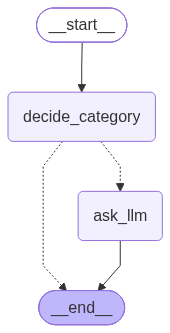

In [29]:
from IPython.display import Image, display

builder = StateGraph(TriageState)
builder.add_node("decide_category", decide_category)
builder.add_node("ask_llm", ask_llm)
builder.add_edge(START, "decide_category")
builder.add_conditional_edges("decide_category", route_after_decide, ["ask_llm", END])
builder.add_edge("ask_llm", END)
triage_graph = builder.compile()

display(Image(triage_graph.get_graph().draw_mermaid_png()))

Der Graph heisst `triage_graph`, damit er unseren Agenten `graph` nicht überschreibt.
Jetzt vier Fragen:

In [30]:
for question in ["Wie viel Gepäck darf ich in Economy Classic mitnehmen?",
                 "Mein Flug wurde annulliert. Bekomme ich mein Geld zurück?",
                 "Was kostet eine Umbuchung in Economy Classic?",
                 "Bist du der offizielle Kundendienst von SWISS?"]:
    result = triage_graph.invoke({"question": question})
    print(f"{question:58} {result['category']:8} TEV1-Sicherheit {result['confidence']:.2f}"
          f"  -> entschieden von {result['decided_by']}")

Wie viel Gepäck darf ich in Economy Classic mitnehmen?     baggage  TEV1-Sicherheit 0.90  -> entschieden von TEV1


Mein Flug wurde annulliert. Bekomme ich mein Geld zurück?  refund   TEV1-Sicherheit 0.98  -> entschieden von TEV1


Was kostet eine Umbuchung in Economy Classic?              fare     TEV1-Sicherheit 0.46  -> entschieden von LLM


Bist du der offizielle Kundendienst von SWISS?             other    TEV1-Sicherheit 0.63  -> entschieden von TEV1


Wo TEV1 sicher war, hat es allein entschieden. Wo es unsicher war, hat der Graph das
grosse Modell gefragt. Im Trace sieht man, wie oft das nötig war — und damit, wie
viele Aufrufe des grossen Modells das kleine einspart.

> **Vereinfachung.** Den Schwellwert 0,6 haben wir an ein paar Beispielen abgelesen.
> Ob eine `confidence` von 0,6 wirklich heisst «in 60 von 100 Fällen richtig», ist
> nicht gesagt. Im Ernstfall legt man den Schwellwert mit einer Testsammlung fest,
> wie wir sie in Woche 9 aufbauen.

## Aufgaben bis zur nächsten Woche:

- **Eigenes Werkzeug:** Schreib ein Werkzeug für euren Use-Case und häng es in
  `tools` ein. Denk an Name, Parameter und Docstring — sie entscheiden.
- **Websuche eingrenzen:** `TavilySearch` nimmt auch `include_domains`, zum Beispiel
  `TavilySearch(max_results=3, include_domains=["swiss.com"])`. Was ändert sich an
  Antworten und Quellen? Wann ist eine offene Suche besser?
- **Fehlerbehandlung:** Schaue, wie die Fehlerbehandlung gewährleistet ist. Was passiert, wenn ein Werkzeug abstürzt? Wie reagiert das Modell? --> LangSmith
- **MCP:** Benutze einen eigenen MCP Server.
- **Decision Models** Nutze TEV1 in einem Node.

## Baustein zum Mitnehmen

In [31]:
import sys
import requests
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain.messages import ToolMessage
from langchain_tavily import TavilySearch
from langgraph.prebuilt import ToolNode
from langgraph.types import RetryPolicy

client = MultiServerMCPClient({
    "swiss": {"command": sys.executable, "args": ["05_custom_mcp_server.py"], "transport": "stdio"}
})
mcp_tools = await client.get_tools()

tools = [fare_lookup] + mcp_tools
if os.environ.get("TAVILY_API_KEY"):
    tools.append(TavilySearch(max_results=3))

llm_with_tools = llm.bind_tools(tools)


async def handle_tool_errors(request, handler):
    try:
        return await handler(request)
    except ConnectionError:
        raise
    except Exception as e:
        return ToolMessage(content=f"Fehler in {request.tool_call['name']}: {e}. "
                                   "Sag der Person, was nicht geklappt hat.",
                           tool_call_id=request.tool_call["id"])


tool_node = ToolNode(tools, awrap_tool_call=handle_tool_errors)


async def call_tools(state: AgentState):
    result = await tool_node.ainvoke(state)
    return {"messages": result["messages"],
            "tools_used": [c["name"] for c in state["messages"][-1].tool_calls]}


def build_graph():
    builder = StateGraph(AgentState)
    builder.add_node("classify", classify)
    builder.add_node("reject", reject)
    builder.add_node("answer", answer)
    builder.add_node("tools", call_tools,
                     retry_policy=RetryPolicy(max_attempts=3, retry_on=ConnectionError))
    builder.add_node("respond", respond)
    builder.add_edge(START, "classify")
    builder.add_conditional_edges("classify", route_after_classify, ["answer", "reject"])
    builder.add_edge("reject", END)
    builder.add_conditional_edges("answer", route_after_answer, ["tools", "respond"])
    builder.add_edge("tools", "answer")
    builder.add_edge("respond", END)
    return builder.compile()


graph = build_graph()


DECISION_MODEL = "tev1:0.8b"
DECISION_URL = LLM_BASE_URL + "/decisions"


def decide(text, questions):
    response = requests.post(
        DECISION_URL,
        headers={"Authorization": f"Bearer {os.environ['LITELLM_API_KEY']}"},
        json={"model": DECISION_MODEL, "input": text, "questions": questions},
        timeout=60,
    )
    response.raise_for_status()
    return response.json()["answers"]